# Precision Pest Control Via Object Detection
### EnviroPest Solutions — Automated Pest Classification Pipeline

**Objective:** Build and compare two deep learning models for classifying 12 agricultural pest species from images:
1. **Custom CNN** — trained from scratch
2. **Fine-Tuned ResNet-50** — transfer learning from ImageNet

**Pest Classes (12):** Ants, Bees, Beetles, Caterpillars, Earthworms, Earwigs, Grasshoppers, Moths, Slugs, Snails, Wasps, Weevils

**Evaluation Criteria:** Accuracy, Precision, Recall, F1-Score, Confusion Matrix

## Workflow

1. **Configuration & Imports** — single config point, library imports, seed setting
2. **Data Loading & Exploration** — directory walk, DataFrame creation, class distribution
3. **Data Visualization** — sample images per class, distribution plots
4. **Data Preprocessing** — train/val/test split, augmentation, generators
5. **Model 1: Custom CNN** — architecture, training, evaluation
6. **Model 2: Fine-Tuned ResNet-50** — transfer learning, training, evaluation
7. **Model Comparison & Selection** — side-by-side metrics, best model selection
8. **Inference Pipeline** — single-image prediction function
9. **Model Export** — save best model for deployment

## 1. Configuration & Imports

In [3]:
# ============================================================
# CONFIGURATION — CHANGE THIS PATH TO YOUR DATASET ROOT
# ============================================================
# The DATA_PATH should point to the folder containing the 12
# pest sub-folders (ants/, bees/, beetle/, etc.)
# ============================================================

DATA_PATH = r"/content/dataset"

# Hyperparameters
IMAGE_SIZE     = (224, 224)
BATCH_SIZE     = 32
EPOCHS         = 10
LEARNING_RATE  = 0.0001
PATIENCE       = 5
SEED           = 42
NUM_CLASSES    = 12
TEST_SPLIT     = 0.20
VAL_SPLIT      = 0.20

In [4]:
# Core
import os
import random
import warnings
import numpy as np
import pandas as pd
warnings.filterwarnings('ignore')

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Scikit-learn
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# TensorFlow / Keras
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, models, Model
from tensorflow.keras.preprocessing.image import (
    ImageDataGenerator,
    load_img
)
from tensorflow.keras.layers import (
    Dense, Dropout, GlobalAveragePooling2D,
    BatchNormalization
)
from tensorflow.keras.callbacks import (
    EarlyStopping, ModelCheckpoint, ReduceLROnPlateau
)
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.applications import ResNet50
from tensorflow.keras.applications.resnet50 import preprocess_input as resnet_preprocess

# OpenCV
import cv2

print(f"TensorFlow version : {tf.__version__}")
print(f"GPU available      : {len(tf.config.list_physical_devices('GPU')) > 0}")
print(f"NumPy version      : {np.__version__}")
print(f"Pandas version     : {pd.__version__}")

TensorFlow version : 2.19.0
GPU available      : True
NumPy version      : 2.0.2
Pandas version     : 2.2.2


In [5]:
# Seed everything for reproducibility
def seed_everything(seed):
    """Set seeds for all libraries to ensure reproducibility."""
    os.environ['PYTHONHASHSEED'] = str(seed)
    os.environ['TF_DETERMINISTIC_OPS'] = '1'
    random.seed(seed)
    np.random.seed(seed)
    tf.random.set_seed(seed)
    print(f"[INFO] All seeds set to {seed}")

seed_everything(SEED)

[INFO] All seeds set to 42


## 2. Data Loading & Exploration

In [6]:
# Walk the dataset directory and report structure
def get_dataset_info(root_dir):
    """Walk through the data directory, count images per class."""
    class_counts = {}
    for dirpath, dirnames, filenames in os.walk(root_dir):
        imgs = [f for f in filenames if f.lower().endswith(('.png', '.jpg', '.jpeg'))]
        if imgs:
            class_name = os.path.basename(dirpath)
            class_counts[class_name] = len(imgs)
            print(f"  {class_name:<15s} → {len(imgs):>4d} images")
    total = sum(class_counts.values())
    print(f"\n  {'TOTAL':<15s} → {total:>4d} images across {len(class_counts)} classes")
    return class_counts

print("Dataset Structure:")
print("=" * 40)
class_counts = get_dataset_info(DATA_PATH)

Dataset Structure:
  grasshopper     →  485 images
  ants            →  499 images
  snail           →  500 images
  moth            →  497 images
  wasp            →  498 images
  slug            →  391 images
  weevil          →  485 images
  earthworms      →  323 images
  earwig          →  466 images
  bees            →  500 images
  catterpillar    →  434 images
  beetle          →  416 images

  TOTAL           → 5494 images across 12 classes


In [7]:
# Build a DataFrame of all image paths and labels
image_paths, labels = [], []

for folder_name in sorted(os.listdir(DATA_PATH)):
    folder_path = os.path.join(DATA_PATH, folder_name)
    if not os.path.isdir(folder_path):
        continue
    for img_name in os.listdir(folder_path):
        if img_name.lower().endswith(('.png', '.jpg', '.jpeg')):
            image_paths.append(os.path.join(folder_path, img_name))
            labels.append(folder_name)

df = pd.DataFrame({'image_path': image_paths, 'label': labels})
df = df.sample(frac=1, random_state=SEED).reset_index(drop=True)

print(f"Total images : {len(df)}")
print(f"Unique classes: {df['label'].nunique()}")
print(f"\nClass list   : {sorted(df['label'].unique())}")
print(f"\nSample rows:")
df.head(10)

Total images : 5494
Unique classes: 12

Class list   : ['ants', 'bees', 'beetle', 'catterpillar', 'earthworms', 'earwig', 'grasshopper', 'moth', 'slug', 'snail', 'wasp', 'weevil']

Sample rows:


,image_path,label
0,/content/dataset/earthworms/earthworms (164).jpg,earthworms
1,/content/dataset/bees/bees (431).jpg,bees
2,/content/dataset/earthworms/earthworms (228).jpg,earthworms
3,/content/dataset/beetle/beetle (73).jpg,beetle
4,/content/dataset/wasp/wasp (517).jpg,wasp
5,/content/dataset/slug/slug (225).jpg,slug
6,/content/dataset/ants/ants (227).jpg,ants
7,/content/dataset/weevil/Weevil (456).jpg,weevil
8,/content/dataset/snail/snail (31).jpg,snail
9,/content/dataset/beetle/beetle (102).jpg,beetle


## 3. Data Visualization

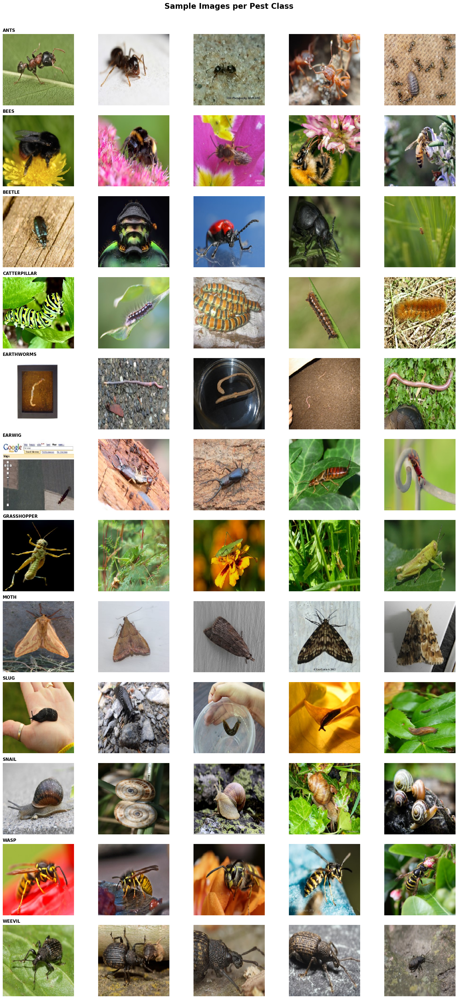

In [8]:
# Display 5 random sample images per pest class
fig, axes = plt.subplots(NUM_CLASSES, 5, figsize=(18, 3 * NUM_CLASSES))
fig.suptitle("Sample Images per Pest Class", fontsize=20, fontweight='bold', y=1.01)

for row_idx, class_name in enumerate(sorted(df['label'].unique())):
    class_imgs = df[df['label'] == class_name]['image_path'].tolist()
    sampled = random.sample(class_imgs, min(5, len(class_imgs)))
    for col_idx, img_path in enumerate(sampled):
        img = load_img(img_path, target_size=IMAGE_SIZE)
        axes[row_idx, col_idx].imshow(img)
        axes[row_idx, col_idx].axis('off')
        if col_idx == 0:
            axes[row_idx, col_idx].set_title(
                class_name.upper(), fontsize=11, fontweight='bold', loc='left'
            )

plt.tight_layout()
plt.show()

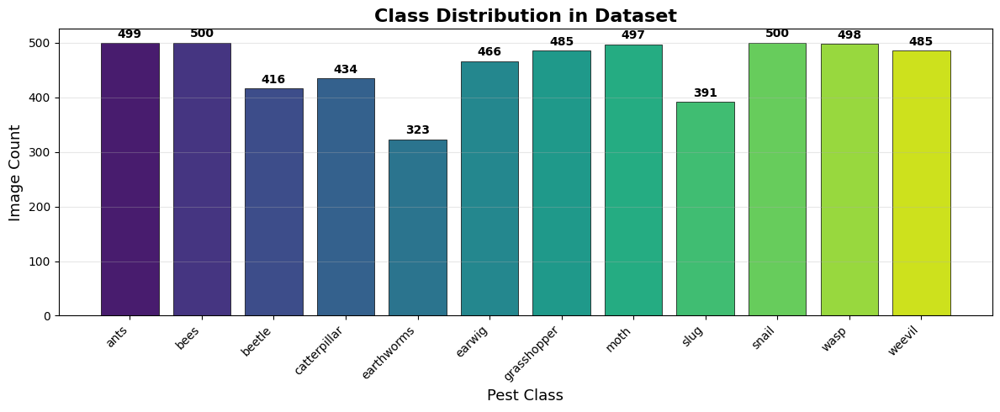


Min class: earthworms (323 images)
Max class: bees (500 images)
Imbalance ratio (max/min): 1.55


In [9]:
# Class distribution bar chart
counts = df['label'].value_counts().sort_index()

fig, ax = plt.subplots(figsize=(12, 5))
palette = sns.color_palette("viridis", n_colors=NUM_CLASSES)
bars = ax.bar(counts.index, counts.values, color=palette, edgecolor='black', linewidth=0.5)

# Annotate bars
for bar, count in zip(bars, counts.values):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 5,
            str(count), ha='center', va='bottom', fontsize=10, fontweight='bold')

ax.set_xlabel("Pest Class", fontsize=13)
ax.set_ylabel("Image Count", fontsize=13)
ax.set_title("Class Distribution in Dataset", fontsize=16, fontweight='bold')
ax.set_xticklabels(counts.index, rotation=45, ha='right')
ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

# Imbalance ratio
print(f"\nMin class: {counts.idxmin()} ({counts.min()} images)")
print(f"Max class: {counts.idxmax()} ({counts.max()} images)")
print(f"Imbalance ratio (max/min): {counts.max() / counts.min():.2f}")

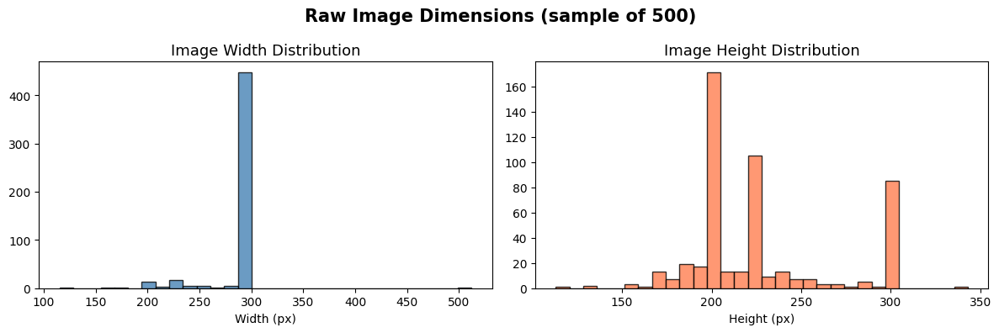

Width  — min: 115, max: 512, mean: 292
Height — min: 113, max: 343, mean: 226


In [10]:
# Analyze image dimensions distribution
widths, heights = [], []
sample_paths = df['image_path'].sample(min(500, len(df)), random_state=SEED)

for path in sample_paths:
    img = cv2.imread(path)
    if img is not None:
        h, w = img.shape[:2]
        heights.append(h)
        widths.append(w)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(widths, bins=30, color='steelblue', edgecolor='black', alpha=0.8)
axes[0].set_title("Image Width Distribution", fontsize=13)
axes[0].set_xlabel("Width (px)")

axes[1].hist(heights, bins=30, color='coral', edgecolor='black', alpha=0.8)
axes[1].set_title("Image Height Distribution", fontsize=13)
axes[1].set_xlabel("Height (px)")

plt.suptitle("Raw Image Dimensions (sample of 500)", fontsize=15, fontweight='bold')
plt.tight_layout()
plt.show()

print(f"Width  — min: {min(widths)}, max: {max(widths)}, mean: {np.mean(widths):.0f}")
print(f"Height — min: {min(heights)}, max: {max(heights)}, mean: {np.mean(heights):.0f}")

## 4. Data Preprocessing & Augmentation

In [11]:
# Stratified train / validation / test split
train_df, test_df = train_test_split(
    df, test_size=TEST_SPLIT, random_state=SEED, stratify=df['label']
)
train_df, val_df = train_test_split(
    train_df, test_size=VAL_SPLIT, random_state=SEED, stratify=train_df['label']
)

print(f"Training set   : {len(train_df):>5d} images ({len(train_df)/len(df)*100:.1f}%)")
print(f"Validation set : {len(val_df):>5d} images ({len(val_df)/len(df)*100:.1f}%)")
print(f"Test set       : {len(test_df):>5d} images ({len(test_df)/len(df)*100:.1f}%)")
print(f"{'─'*40}")
print(f"Total          : {len(train_df)+len(val_df)+len(test_df):>5d} images")

Training set   :  3516 images (64.0%)
Validation set :   879 images (16.0%)
Test set       :  1099 images (20.0%)
────────────────────────────────────────
Total          :  5494 images


---
## 5. Model 1 — Custom CNN from Scratch

In [12]:
# Data generators for the Custom CNN (rescale to [0,1] + augmentation)
train_datagen_cnn = ImageDataGenerator(
    rescale=1./255,
    rotation_range=25,
    width_shift_range=0.2,
    height_shift_range=0.2,
    shear_range=0.15,
    zoom_range=0.2,
    horizontal_flip=True,
    brightness_range=[0.8, 1.2],
    fill_mode='nearest'
)

val_test_datagen_cnn = ImageDataGenerator(rescale=1./255)

train_gen_cnn = train_datagen_cnn.flow_from_dataframe(
    train_df, x_col='image_path', y_col='label',
    target_size=IMAGE_SIZE, batch_size=BATCH_SIZE,
    class_mode='categorical', shuffle=True, seed=SEED
)

val_gen_cnn = val_test_datagen_cnn.flow_from_dataframe(
    val_df, x_col='image_path', y_col='label',
    target_size=IMAGE_SIZE, batch_size=BATCH_SIZE,
    class_mode='categorical', shuffle=False
)

test_gen_cnn = val_test_datagen_cnn.flow_from_dataframe(
    test_df, x_col='image_path', y_col='label',
    target_size=IMAGE_SIZE, batch_size=BATCH_SIZE,
    class_mode='categorical', shuffle=False
)

# Store class indices for later
class_indices = train_gen_cnn.class_indices
class_names = list(class_indices.keys())
print(f"\nClass mapping: {class_indices}")

Found 3516 validated image filenames belonging to 12 classes.
Found 879 validated image filenames belonging to 12 classes.
Found 1099 validated image filenames belonging to 12 classes.

Class mapping: {'ants': 0, 'bees': 1, 'beetle': 2, 'catterpillar': 3, 'earthworms': 4, 'earwig': 5, 'grasshopper': 6, 'moth': 7, 'slug': 8, 'snail': 9, 'wasp': 10, 'weevil': 11}


In [13]:
# Custom CNN Architecture
cnn_model = models.Sequential([
    # Block 1
    layers.Conv2D(32, (3, 3), padding='same', activation='relu',
                  input_shape=(*IMAGE_SIZE, 3)),
    layers.BatchNormalization(),
    layers.Conv2D(32, (3, 3), padding='same', activation='relu'),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),
    layers.Dropout(0.25),

    # Block 2
    layers.Conv2D(64, (3, 3), padding='same', activation='relu'),
    layers.BatchNormalization(),
    layers.Conv2D(64, (3, 3), padding='same', activation='relu'),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),
    layers.Dropout(0.25),

    # Block 3
    layers.Conv2D(128, (3, 3), padding='same', activation='relu'),
    layers.BatchNormalization(),
    layers.Conv2D(128, (3, 3), padding='same', activation='relu'),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),
    layers.Dropout(0.30),

    # Block 4
    layers.Conv2D(256, (3, 3), padding='same', activation='relu'),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),
    layers.Dropout(0.30),

    # Classifier Head
    layers.GlobalAveragePooling2D(),
    layers.Dense(512, activation='relu'),
    layers.BatchNormalization(),
    layers.Dropout(0.5),
    layers.Dense(256, activation='relu'),
    layers.Dropout(0.3),
    layers.Dense(NUM_CLASSES, activation='softmax')
], name='Custom_CNN')

cnn_model.summary()

Model: "Custom_CNN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 224, 224, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 224, 224, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 224, 224, 32)   │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 224, 224, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 112, 112, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 112, 112, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 112, 112, 64)   │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 112, 112, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 56, 56, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 56, 56, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 56, 56, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 56, 56, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 28, 28, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_6           │ (None, 28, 28, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 14, 14, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼─────────────

 Total params: 853,036 (3.25 MB)

 Trainable params: 850,604 (3.24 MB)

 Non-trainable params: 2,432 (9.50 KB)

In [14]:
# Compile CNN
cnn_model.compile(
    optimizer=Adam(learning_rate=LEARNING_RATE),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

# Callbacks
cnn_callbacks = [
    EarlyStopping(
        monitor='val_loss', patience=PATIENCE,
        restore_best_weights=True, verbose=1
    ),
    ReduceLROnPlateau(
        monitor='val_loss', factor=0.5,
        patience=3, min_lr=1e-7, verbose=1
    )
]

# Train
print("\n" + "="*50)
print("TRAINING CUSTOM CNN")
print("="*50)

cnn_history = cnn_model.fit(
    train_gen_cnn,
    steps_per_epoch=len(train_gen_cnn),
    validation_data=val_gen_cnn,
    validation_steps=len(val_gen_cnn),
    epochs=EPOCHS,
    callbacks=cnn_callbacks,
    verbose=1
)


TRAINING CUSTOM CNN
Epoch 1/10
110/110 ━━━━━━━━━━━━━━━━━━━━ 94s 767ms/step - accuracy: 0.1069 - loss: 3.2561 - val_accuracy: 0.0762 - val_loss: 2.5303 - learning_rate: 1.0000e-04
Epoch 2/10
110/110 ━━━━━━━━━━━━━━━━━━━━ 84s 765ms/step - accuracy: 0.1359 - loss: 2.9652 - val_accuracy: 0.0785 - val_loss: 2.8699 - learning_rate: 1.0000e-04
Epoch 3/10
110/110 ━━━━━━━━━━━━━━━━━━━━ 88s 796ms/step - accuracy: 0.1533 - loss: 2.8904 - val_accuracy: 0.0819 - val_loss: 3.2630 - learning_rate: 1.0000e-04
Epoch 4/10
110/110 ━━━━━━━━━━━━━━━━━━━━ 0s 745ms/step - accuracy: 0.1509 - loss: 2.8455
Epoch 4: ReduceLROnPlateau reducing learning rate to 4.999999873689376e-05.
110/110 ━━━━━━━━━━━━━━━━━━━━ 85s 769ms/step - accuracy: 0.1539 - loss: 2.8273 - val_accuracy: 0.1092 - val_loss: 3.0682 - learning_rate: 1.0000e-04
Epoch 5/10
110/110 ━━━━━━━━━━━━━━━━━━━━ 84s 764ms/step - accuracy: 0.1647 - loss: 2.7031 - val_accuracy: 0.1229 - val_loss: 2.9936 - learning_rate: 5.0000e-05
Epoch 6/10
110/110 ━━━━━━━━━━━━

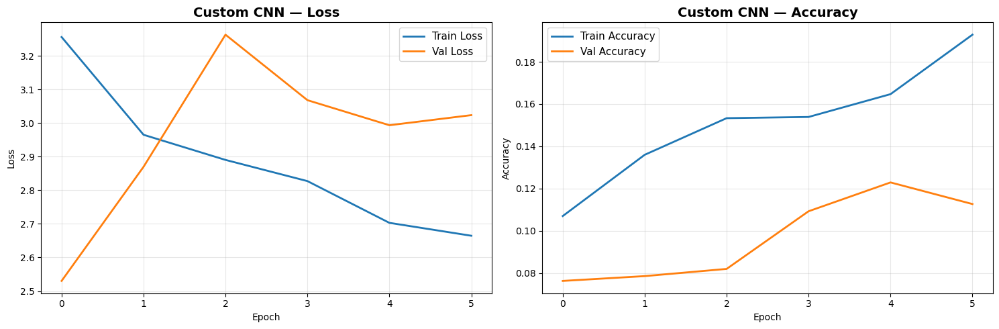

In [15]:
# Plot CNN training curves
def plot_training_curves(history, model_name):
    """Plot loss and accuracy curves side by side."""
    fig, axes = plt.subplots(1, 2, figsize=(15, 5))

    # Loss
    axes[0].plot(history.history['loss'], label='Train Loss', linewidth=2)
    axes[0].plot(history.history['val_loss'], label='Val Loss', linewidth=2)
    axes[0].set_title(f'{model_name} — Loss', fontsize=14, fontweight='bold')
    axes[0].set_xlabel('Epoch')
    axes[0].set_ylabel('Loss')
    axes[0].legend(fontsize=11)
    axes[0].grid(alpha=0.3)

    # Accuracy
    axes[1].plot(history.history['accuracy'], label='Train Accuracy', linewidth=2)
    axes[1].plot(history.history['val_accuracy'], label='Val Accuracy', linewidth=2)
    axes[1].set_title(f'{model_name} — Accuracy', fontsize=14, fontweight='bold')
    axes[1].set_xlabel('Epoch')
    axes[1].set_ylabel('Accuracy')
    axes[1].legend(fontsize=11)
    axes[1].grid(alpha=0.3)

    plt.tight_layout()
    plt.show()

plot_training_curves(cnn_history, "Custom CNN")


Custom CNN — Test Results
Test Loss     : 2.5316
Test Accuracy : 0.0792 (7.92%)

──────────────────────────────────────────────────
Classification Report:
──────────────────────────────────────────────────
              precision    recall  f1-score   support

        ants       0.00      0.00      0.00       100
        bees       0.00      0.00      0.00       100
      beetle       0.00      0.00      0.00        83
catterpillar       0.06      0.21      0.10        87
  earthworms       0.00      0.00      0.00        65
      earwig       0.09      0.74      0.15        93
 grasshopper       0.00      0.00      0.00        97
        moth       0.00      0.00      0.00        99
        slug       0.00      0.00      0.00        78
       snail       0.00      0.00      0.00       100
        wasp       0.00      0.00      0.00       100
      weevil       0.00      0.00      0.00        97

    accuracy                           0.08      1099
   macro avg       0.01      0.08  

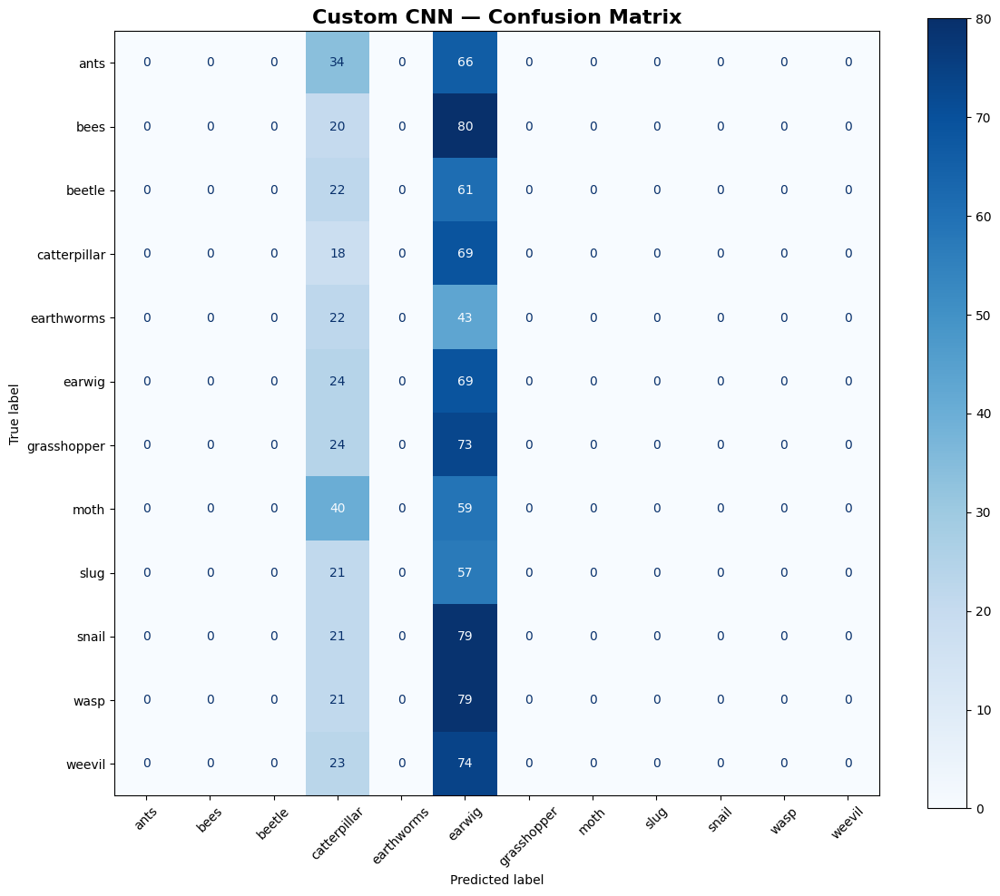

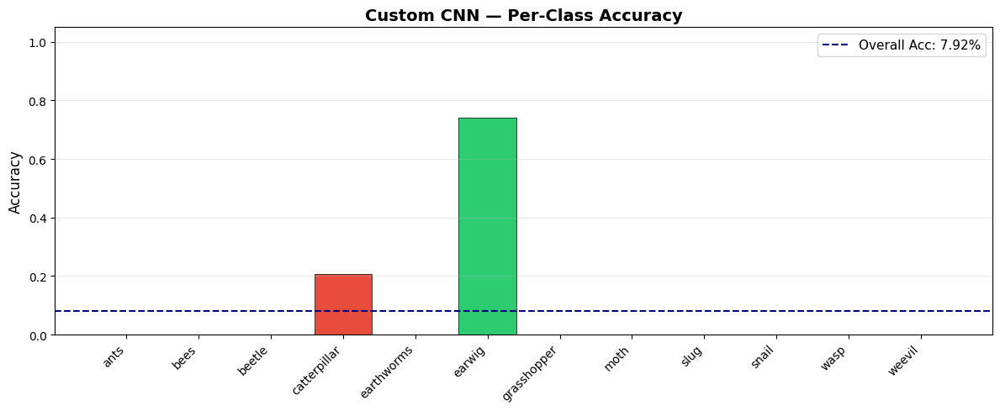

In [16]:
# Evaluate Custom CNN on test set
def evaluate_model(model, test_generator, model_name):
    """Full evaluation: loss, accuracy, classification report, confusion matrix."""
    # Test loss & accuracy
    test_loss, test_acc = model.evaluate(test_generator, steps=len(test_generator), verbose=0)
    print(f"\n{'='*50}")
    print(f"{model_name} — Test Results")
    print(f"{'='*50}")
    print(f"Test Loss     : {test_loss:.4f}")
    print(f"Test Accuracy : {test_acc:.4f} ({test_acc*100:.2f}%)")

    # Predictions
    test_generator.reset()
    y_pred_probs = model.predict(test_generator, steps=len(test_generator), verbose=0)
    y_pred = np.argmax(y_pred_probs, axis=1)
    y_true = test_generator.classes[:len(y_pred)]
    labels = list(test_generator.class_indices.keys())

    # Classification Report
    print(f"\n{'─'*50}")
    print("Classification Report:")
    print(f"{'─'*50}")
    report = classification_report(y_true, y_pred, target_names=labels, output_dict=True)
    print(classification_report(y_true, y_pred, target_names=labels))

    # Confusion Matrix
    cm = confusion_matrix(y_true, y_pred)
    fig, ax = plt.subplots(figsize=(12, 10))
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=labels)
    disp.plot(ax=ax, cmap='Blues', xticks_rotation=45, values_format='d')
    ax.set_title(f"{model_name} — Confusion Matrix", fontsize=16, fontweight='bold')
    plt.tight_layout()
    plt.show()

    # Per-class accuracy bar chart
    per_class_acc = cm.diagonal() / cm.sum(axis=1)
    fig, ax = plt.subplots(figsize=(12, 5))
    colors = ['#2ecc71' if acc >= 0.7 else '#e74c3c' for acc in per_class_acc]
    bars = ax.bar(labels, per_class_acc, color=colors, edgecolor='black', linewidth=0.5)
    ax.axhline(y=test_acc, color='navy', linestyle='--', linewidth=1.5, label=f'Overall Acc: {test_acc:.2%}')
    ax.set_ylabel("Accuracy", fontsize=12)
    ax.set_title(f"{model_name} — Per-Class Accuracy", fontsize=14, fontweight='bold')
    ax.set_xticklabels(labels, rotation=45, ha='right')
    ax.set_ylim(0, 1.05)
    ax.legend(fontsize=11)
    ax.grid(axis='y', alpha=0.3)
    plt.tight_layout()
    plt.show()

    return {
        'test_loss': test_loss,
        'test_accuracy': test_acc,
        'y_pred': y_pred,
        'y_true': y_true,
        'report': report,
        'confusion_matrix': cm
    }

cnn_results = evaluate_model(cnn_model, test_gen_cnn, "Custom CNN")

---
## 6. Model 2 — Fine-Tuned ResNet-50 (Transfer Learning)

In [17]:
# Data generators for ResNet-50 (uses ResNet preprocessing, not simple /255)
train_datagen_resnet = ImageDataGenerator(
    preprocessing_function=resnet_preprocess,
    rotation_range=25,
    width_shift_range=0.2,
    height_shift_range=0.2,
    shear_range=0.15,
    zoom_range=0.2,
    horizontal_flip=True,
    brightness_range=[0.8, 1.2],
    fill_mode='nearest'
)

val_test_datagen_resnet = ImageDataGenerator(
    preprocessing_function=resnet_preprocess
)

train_gen_resnet = train_datagen_resnet.flow_from_dataframe(
    train_df, x_col='image_path', y_col='label',
    target_size=IMAGE_SIZE, batch_size=BATCH_SIZE,
    class_mode='categorical', shuffle=True, seed=SEED
)

val_gen_resnet = val_test_datagen_resnet.flow_from_dataframe(
    val_df, x_col='image_path', y_col='label',
    target_size=IMAGE_SIZE, batch_size=BATCH_SIZE,
    class_mode='categorical', shuffle=False
)

test_gen_resnet = val_test_datagen_resnet.flow_from_dataframe(
    test_df, x_col='image_path', y_col='label',
    target_size=IMAGE_SIZE, batch_size=BATCH_SIZE,
    class_mode='categorical', shuffle=False
)

Found 3516 validated image filenames belonging to 12 classes.
Found 879 validated image filenames belonging to 12 classes.
Found 1099 validated image filenames belonging to 12 classes.


In [18]:
# Load pre-trained ResNet-50 base (frozen)
base_model = ResNet50(
    include_top=False,
    weights='imagenet',
    input_shape=(*IMAGE_SIZE, 3)
)

# Freeze all layers in the base model
base_model.trainable = False

# Build custom classification head on top
inputs = base_model.input
x = base_model.output
x = GlobalAveragePooling2D()(x)
x = Dense(512, activation='relu')(x)
x = BatchNormalization()(x)
x = Dropout(0.5)(x)
x = Dense(256, activation='relu')(x)
x = BatchNormalization()(x)
x = Dropout(0.3)(x)
outputs = Dense(NUM_CLASSES, activation='softmax')(x)

resnet_model = Model(inputs=inputs, outputs=outputs, name='ResNet50_FineTuned')

print(f"Total layers       : {len(resnet_model.layers)}")
print(f"Trainable params   : {sum(tf.keras.backend.count_params(w) for w in resnet_model.trainable_weights):,}")
print(f"Non-trainable params: {sum(tf.keras.backend.count_params(w) for w in resnet_model.non_trainable_weights):,}")
print()
resnet_model.summary(show_trainable=True, expand_nested=False)

94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Total layers       : 183
Trainable params   : 1,185,036
Non-trainable params: 23,589,248



Model: "ResNet50_FineTuned"

┏━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━┳━━━━━━━━━━━━━━━━┳━━━━━━━┓
┃ Layer (type)      ┃ Output Shape    ┃   Param # ┃ Connected to   ┃ Trai… ┃
┡━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━╇━━━━━━━━━━━━━━━━╇━━━━━━━┩
│ input_layer_1     │ (None, 224,     │         0 │ -              │   -   │
│ (InputLayer)      │ 224, 3)         │           │                │       │
├───────────────────┼─────────────────┼───────────┼────────────────┼───────┤
│ conv1_pad         │ (None, 230,     │         0 │ input_layer_1… │   -   │
│ (ZeroPadding2D)   │ 230, 3)         │           │                │       │
├───────────────────┼─────────────────┼───────────┼────────────────┼───────┤
│ conv1_conv        │ (None, 112,     │     9,472 │ conv1_pad[0][… │   N   │
│ (Conv2D)          │ 112, 64)        │           │                │       │
├───────────────────┼─────────────────┼───────────┼────────────────┼───────┤
│ conv1_bn          │ (None, 112,     │       256 │ conv1_conv[0]… │   N   │
│ (BatchNormalizat… │ 112, 64)        │           │                │       │
├───────────────────┼─────────────────┼───────────┼────────────────┼───────┤
│ conv1_relu        │ (None, 112,     │         0 │ conv1_bn[0][0] │   -   │
│ (Activation)      │ 112, 64)        │           │                │       │
├───────────────────┼─────────────────┼───────────┼────────────────┼───────┤
│ pool1_pad         │ (None, 114,     │         0 │ conv1_relu[0]… │   -   │
│ (ZeroPadding2D)   │ 114, 64)        │           │                │       │
├───────────────────┼─────────────────┼───────────┼────────────────┼───────┤
│ pool1_pool        │ (None, 56, 56,  │         0 │ pool1_pad[0][… │   -   │
│ (MaxPooling2D)    │ 64)             │           │                │       │
├───────────────────┼─────────────────┼───────────┼────────────────┼───────┤
│ conv2_block1_1_c… │ (None, 56, 56,  │     4,160 │ pool1_pool[0]… │   N   │
│ (Conv2D)          │ 64)             │           │                │       │
├───────────────────┼─────────────────┼───────────┼────────────────┼───────┤
│ conv2_block1_1_bn │ (None, 56, 56,  │       256 │ conv2_block1_… │   N   │
│ (BatchNormalizat… │ 64)             │           │                │       │
├───────────────────┼─────────────────┼───────────┼────────────────┼───────┤
│ conv2_block1_1_r… │ (None, 56, 56,  │         0 │ conv2_block1_… │   -   │
│ (Activation)      │ 64)             │           │                │       │
├───────────────────┼─────────────────┼───────────┼────────────────┼───────┤
│ conv2_block1_2_c… │ (None, 56, 56,  │    36,928 │ conv2_block1_… │   N   │
│ (Conv2D)          │ 64)             │           │                │       │
├───────────────────┼─────────────────┼───────────┼────────────────┼───────┤
│ conv2_block1_2_bn │ (None, 56, 56,  │       256 │ conv2_block1_… │   N   │
│ (BatchNormalizat… │ 64)             │           │                │       │
├───────────────────┼─────────────────┼───────────┼────────────────┼───────┤
│ conv2_block1_2_r… │ (None, 56, 56,  │         0 │ conv2_block1_… │   -   │
│ (Activation)      │ 64)             │           │                │       │
├───────────────────┼─────────────────┼───────────┼────────────────┼───────┤
│ conv2_block1_0_c… │ (None, 56, 56,  │    16,640 │ pool1_pool[0]… │   N   │
│ (Conv2D)          │ 256)            │           │                │       │
├───────────────────┼─────────────────┼───────────┼────────────────┼───────┤
│ conv2_block1_3_c… │ (None, 56, 56,  │    16,640 │ conv2_block1_… │   N   │
│ (Conv2D)          │ 256)            │           │                │       │
├───────────────────┼─────────────────┼───────────┼────────────────┼───────┤
│ conv2_block1_0_bn │ (None, 56, 56,  │     1,024 │ conv2_block1_… │   N   │
│ (BatchNormalizat… │ 256)            │           │                │       │
├───────────────────┼─────────────────┼───────────┼────────────────┼───────┤
│ conv2_block1_3_bn │ (None, 56, 56,  │     1,024 │ conv2_block1_… │   N 

 Total params: 24,774,284 (94.51 MB)

 Trainable params: 1,185,036 (4.52 MB)

 Non-trainable params: 23,589,248 (89.99 MB)

In [19]:
# Phase 1: Train only the classification head (base frozen)
resnet_model.compile(
    optimizer=Adam(learning_rate=LEARNING_RATE),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

resnet_callbacks = [
    EarlyStopping(
        monitor='val_loss', patience=PATIENCE,
        restore_best_weights=True, verbose=1
    ),
    ReduceLROnPlateau(
        monitor='val_loss', factor=0.5,
        patience=3, min_lr=1e-7, verbose=1
    ),
    ModelCheckpoint(
        'best_resnet_phase1.keras',
        monitor='val_accuracy',
        save_best_only=True, verbose=1
    )
]

print("\n" + "="*50)
print("PHASE 1: Training Classification Head (base frozen)")
print("="*50)

resnet_history_p1 = resnet_model.fit(
    train_gen_resnet,
    steps_per_epoch=len(train_gen_resnet),
    validation_data=val_gen_resnet,
    validation_steps=len(val_gen_resnet),
    epochs=EPOCHS,
    callbacks=resnet_callbacks,
    verbose=1
)


PHASE 1: Training Classification Head (base frozen)
Epoch 1/10
110/110 ━━━━━━━━━━━━━━━━━━━━ 0s 557ms/step - accuracy: 0.2307 - loss: 2.6505
Epoch 1: val_accuracy improved from None to 0.69966, saving model to best_resnet_phase1.keras

Epoch 1: finished saving model to best_resnet_phase1.keras
110/110 ━━━━━━━━━━━━━━━━━━━━ 78s 635ms/step - accuracy: 0.3683 - loss: 2.0956 - val_accuracy: 0.6997 - val_loss: 1.0023 - learning_rate: 1.0000e-04
Epoch 2/10
110/110 ━━━━━━━━━━━━━━━━━━━━ 0s 561ms/step - accuracy: 0.6456 - loss: 1.1873
Epoch 2: val_accuracy improved from 0.69966 to 0.81229, saving model to best_resnet_phase1.keras

Epoch 2: finished saving model to best_resnet_phase1.keras
110/110 ━━━━━━━━━━━━━━━━━━━━ 68s 618ms/step - accuracy: 0.6615 - loss: 1.1225 - val_accuracy: 0.8123 - val_loss: 0.6533 - learning_rate: 1.0000e-04
Epoch 3/10
110/110 ━━━━━━━━━━━━━━━━━━━━ 0s 557ms/step - accuracy: 0.7305 - loss: 0.8805
Epoch 3: val_accuracy improved from 0.81229 to 0.83845, saving model to best

In [20]:
# Phase 2: Unfreeze top layers of ResNet and fine-tune with lower LR
# Unfreeze the last 30 layers for fine-tuning
base_model.trainable = True
for layer in base_model.layers[:-30]:
    layer.trainable = False

trainable_count = sum(1 for layer in resnet_model.layers if layer.trainable)
print(f"Trainable layers after unfreezing: {trainable_count}")

# Re-compile with a much lower learning rate
resnet_model.compile(
    optimizer=Adam(learning_rate=LEARNING_RATE / 10),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

resnet_callbacks_p2 = [
    EarlyStopping(
        monitor='val_loss', patience=PATIENCE,
        restore_best_weights=True, verbose=1
    ),
    ReduceLROnPlateau(
        monitor='val_loss', factor=0.5,
        patience=3, min_lr=1e-8, verbose=1
    ),
    ModelCheckpoint(
        'best_resnet_finetuned.keras',
        monitor='val_accuracy',
        save_best_only=True, verbose=1
    )
]

print("\n" + "="*50)
print("PHASE 2: Fine-Tuning Top ResNet Layers")
print("="*50)

resnet_history_p2 = resnet_model.fit(
    train_gen_resnet,
    steps_per_epoch=len(train_gen_resnet),
    validation_data=val_gen_resnet,
    validation_steps=len(val_gen_resnet),
    epochs=EPOCHS,
    callbacks=resnet_callbacks_p2,
    verbose=1
)

Trainable layers after unfreezing: 38

PHASE 2: Fine-Tuning Top ResNet Layers
Epoch 1/10
110/110 ━━━━━━━━━━━━━━━━━━━━ 0s 617ms/step - accuracy: 0.8245 - loss: 0.5416
Epoch 1: val_accuracy improved from None to 0.88737, saving model to best_resnet_finetuned.keras

Epoch 1: finished saving model to best_resnet_finetuned.keras
110/110 ━━━━━━━━━━━━━━━━━━━━ 88s 698ms/step - accuracy: 0.8299 - loss: 0.5271 - val_accuracy: 0.8874 - val_loss: 0.4179 - learning_rate: 1.0000e-05
Epoch 2/10
110/110 ━━━━━━━━━━━━━━━━━━━━ 0s 612ms/step - accuracy: 0.8482 - loss: 0.4578
Epoch 2: val_accuracy did not improve from 0.88737
110/110 ━━━━━━━━━━━━━━━━━━━━ 77s 658ms/step - accuracy: 0.8478 - loss: 0.4605 - val_accuracy: 0.8862 - val_loss: 0.4260 - learning_rate: 1.0000e-05
Epoch 3/10
110/110 ━━━━━━━━━━━━━━━━━━━━ 0s 612ms/step - accuracy: 0.8583 - loss: 0.4284
Epoch 3: val_accuracy improved from 0.88737 to 0.88851, saving model to best_resnet_finetuned.keras

Epoch 3: finished saving model to best_resnet_fine

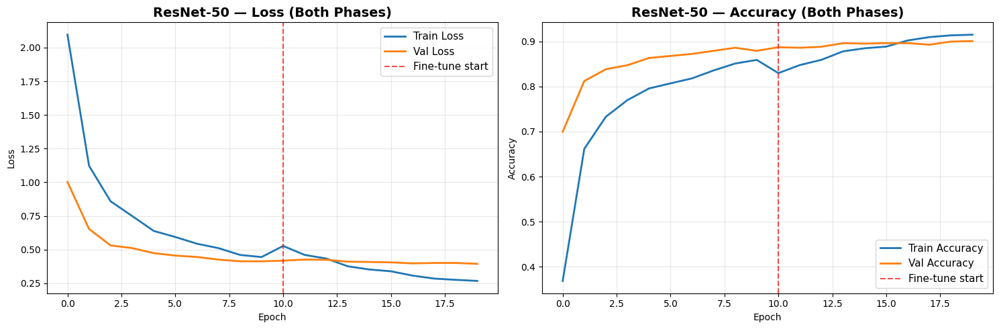

In [21]:
# Combine Phase 1 and Phase 2 histories for plotting
def combine_histories(h1, h2):
    """Merge two Keras history objects into a single dict."""
    combined = {}
    for key in h1.history:
        combined[key] = h1.history[key] + h2.history[key]
    return combined

resnet_combined = combine_histories(resnet_history_p1, resnet_history_p2)
phase1_epochs = len(resnet_history_p1.history['loss'])

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Loss
axes[0].plot(resnet_combined['loss'], label='Train Loss', linewidth=2)
axes[0].plot(resnet_combined['val_loss'], label='Val Loss', linewidth=2)
axes[0].axvline(x=phase1_epochs, color='red', linestyle='--', alpha=0.7, label='Fine-tune start')
axes[0].set_title('ResNet-50 — Loss (Both Phases)', fontsize=14, fontweight='bold')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Loss')
axes[0].legend(fontsize=11)
axes[0].grid(alpha=0.3)

# Accuracy
axes[1].plot(resnet_combined['accuracy'], label='Train Accuracy', linewidth=2)
axes[1].plot(resnet_combined['val_accuracy'], label='Val Accuracy', linewidth=2)
axes[1].axvline(x=phase1_epochs, color='red', linestyle='--', alpha=0.7, label='Fine-tune start')
axes[1].set_title('ResNet-50 — Accuracy (Both Phases)', fontsize=14, fontweight='bold')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Accuracy')
axes[1].legend(fontsize=11)
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()


ResNet-50 Fine-Tuned — Test Results
Test Loss     : 0.3553
Test Accuracy : 0.9035 (90.35%)

──────────────────────────────────────────────────
Classification Report:
──────────────────────────────────────────────────
              precision    recall  f1-score   support

        ants       0.95      0.99      0.97       100
        bees       0.90      0.94      0.92       100
      beetle       0.70      0.78      0.74        83
catterpillar       0.85      0.74      0.79        87
  earthworms       0.85      0.94      0.89        65
      earwig       0.94      0.73      0.82        93
 grasshopper       0.87      0.91      0.89        97
        moth       0.96      0.98      0.97        99
        slug       0.91      0.87      0.89        78
       snail       0.99      0.98      0.98       100
        wasp       0.97      0.96      0.96       100
      weevil       0.91      0.98      0.95        97

    accuracy                           0.90      1099
   macro avg       0.90 

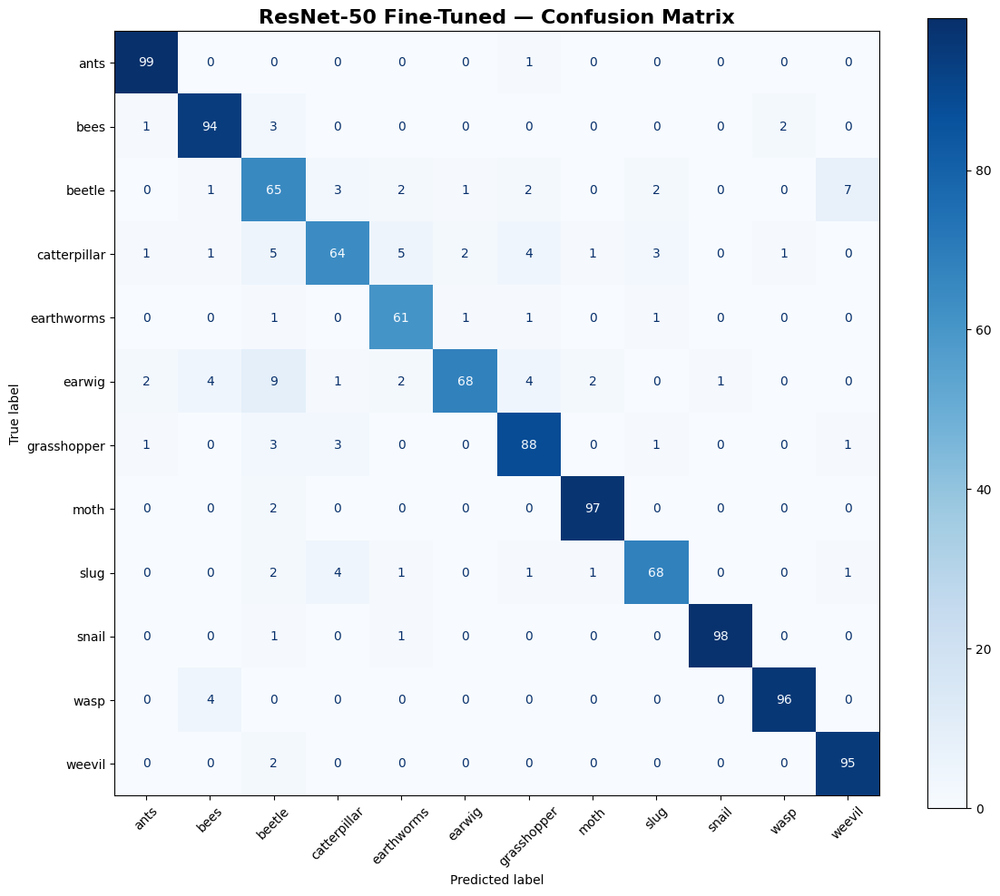

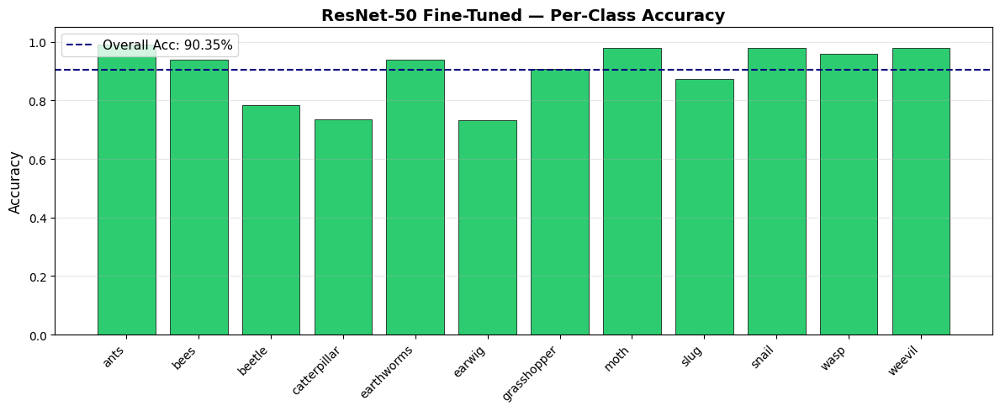

In [22]:
# Evaluate ResNet-50 on test set
resnet_results = evaluate_model(resnet_model, test_gen_resnet, "ResNet-50 Fine-Tuned")

---
## 7. Model Comparison & Selection

MODEL COMPARISON
         Metric Custom CNN ResNet-50 Fine-Tuned
      Test Loss     2.5316               0.3553
  Test Accuracy     0.0792               0.9035
Macro Precision     0.0123               0.9009
   Macro Recall     0.0791               0.8997
 Macro F1-Score     0.0207               0.8982


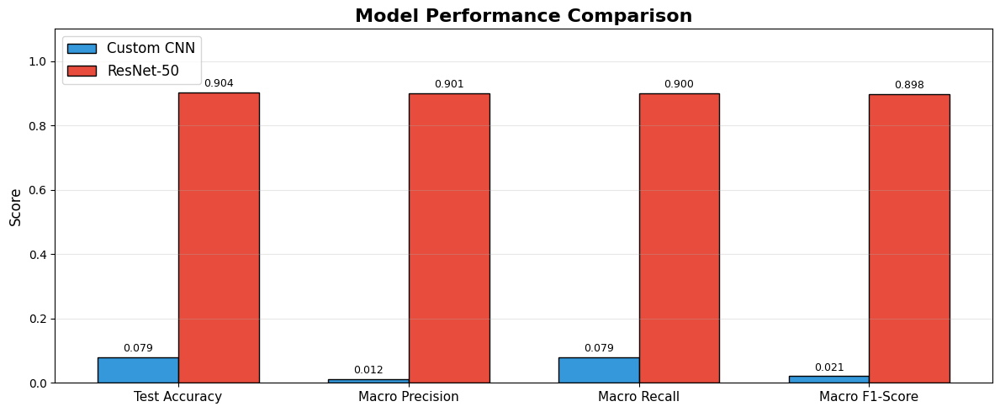

In [23]:
# Side-by-side comparison
comparison = pd.DataFrame({
    'Metric': ['Test Loss', 'Test Accuracy', 'Macro Precision', 'Macro Recall', 'Macro F1-Score'],
    'Custom CNN': [
        f"{cnn_results['test_loss']:.4f}",
        f"{cnn_results['test_accuracy']:.4f}",
        f"{cnn_results['report']['macro avg']['precision']:.4f}",
        f"{cnn_results['report']['macro avg']['recall']:.4f}",
        f"{cnn_results['report']['macro avg']['f1-score']:.4f}"
    ],
    'ResNet-50 Fine-Tuned': [
        f"{resnet_results['test_loss']:.4f}",
        f"{resnet_results['test_accuracy']:.4f}",
        f"{resnet_results['report']['macro avg']['precision']:.4f}",
        f"{resnet_results['report']['macro avg']['recall']:.4f}",
        f"{resnet_results['report']['macro avg']['f1-score']:.4f}"
    ]
})

print("="*60)
print("MODEL COMPARISON")
print("="*60)
print(comparison.to_string(index=False))

# Visual comparison
metrics = ['Test Accuracy', 'Macro Precision', 'Macro Recall', 'Macro F1-Score']
cnn_vals = [
    cnn_results['test_accuracy'],
    cnn_results['report']['macro avg']['precision'],
    cnn_results['report']['macro avg']['recall'],
    cnn_results['report']['macro avg']['f1-score']
]
resnet_vals = [
    resnet_results['test_accuracy'],
    resnet_results['report']['macro avg']['precision'],
    resnet_results['report']['macro avg']['recall'],
    resnet_results['report']['macro avg']['f1-score']
]

x_pos = np.arange(len(metrics))
width = 0.35

fig, ax = plt.subplots(figsize=(12, 5))
bars1 = ax.bar(x_pos - width/2, cnn_vals, width, label='Custom CNN', color='#3498db', edgecolor='black')
bars2 = ax.bar(x_pos + width/2, resnet_vals, width, label='ResNet-50', color='#e74c3c', edgecolor='black')

ax.set_ylabel('Score', fontsize=12)
ax.set_title('Model Performance Comparison', fontsize=16, fontweight='bold')
ax.set_xticks(x_pos)
ax.set_xticklabels(metrics, fontsize=11)
ax.set_ylim(0, 1.1)
ax.legend(fontsize=12)
ax.grid(axis='y', alpha=0.3)

# Annotate
for bar in bars1:
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.01,
            f'{bar.get_height():.3f}', ha='center', va='bottom', fontsize=9)
for bar in bars2:
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.01,
            f'{bar.get_height():.3f}', ha='center', va='bottom', fontsize=9)

plt.tight_layout()
plt.show()

In [24]:
# Select the best model based on test accuracy
if resnet_results['test_accuracy'] >= cnn_results['test_accuracy']:
    best_model = resnet_model
    best_name = "ResNet-50 Fine-Tuned"
    best_acc = resnet_results['test_accuracy']
    best_preprocess = 'resnet'
else:
    best_model = cnn_model
    best_name = "Custom CNN"
    best_acc = cnn_results['test_accuracy']
    best_preprocess = 'rescale'

print(f"\n{'='*50}")
print(f"SELECTED MODEL: {best_name}")
print(f"Test Accuracy  : {best_acc:.4f} ({best_acc*100:.2f}%)")
print(f"{'='*50}")


SELECTED MODEL: ResNet-50 Fine-Tuned
Test Accuracy  : 0.9035 (90.35%)


---
## 8. Inference Pipeline — Single Image Prediction

In [25]:
def predict_pest(image_path, model=None, preprocess_mode=None,
                 class_names=None, top_k=3):
    """
    Predict pest class for a single image.

    Parameters
    ----------
    image_path     : str   — path to the image file
    model          : keras Model (defaults to best_model)
    preprocess_mode: str   — 'resnet' or 'rescale' (defaults to best_preprocess)
    class_names    : list  — ordered class labels (defaults to class_names from training)
    top_k          : int   — number of top predictions to show

    Returns
    -------
    dict with 'predicted_class', 'confidence', 'top_k_predictions'
    """
    if model is None:
        model = best_model
    if preprocess_mode is None:
        preprocess_mode = best_preprocess
    if class_names is None:
        class_names = list(train_gen_cnn.class_indices.keys())

    # Load & preprocess
    img = load_img(image_path, target_size=IMAGE_SIZE)
    img_array = tf.keras.preprocessing.image.img_to_array(img)
    img_array = np.expand_dims(img_array, axis=0)

    if preprocess_mode == 'resnet':
        img_array = resnet_preprocess(img_array.copy())
    else:
        img_array = img_array / 255.0

    # Predict
    preds = model.predict(img_array, verbose=0)[0]
    top_indices = preds.argsort()[::-1][:top_k]

    # Display
    fig, axes = plt.subplots(1, 2, figsize=(12, 4), gridspec_kw={'width_ratios': [1, 1.5]})

    axes[0].imshow(load_img(image_path, target_size=IMAGE_SIZE))
    axes[0].set_title("Input Image", fontsize=13, fontweight='bold')
    axes[0].axis('off')

    top_classes = [class_names[i] for i in top_indices]
    top_probs = [preds[i] for i in top_indices]
    colors = ['#2ecc71' if i == 0 else '#95a5a6' for i in range(top_k)]
    axes[1].barh(top_classes[::-1], top_probs[::-1], color=colors[::-1], edgecolor='black')
    axes[1].set_xlabel('Confidence', fontsize=11)
    axes[1].set_title(f"Top-{top_k} Predictions", fontsize=13, fontweight='bold')
    axes[1].set_xlim(0, 1)

    plt.suptitle(f"Predicted: {class_names[top_indices[0]].upper()}  "
                 f"({preds[top_indices[0]]*100:.1f}%)",
                 fontsize=15, fontweight='bold', color='darkgreen')
    plt.tight_layout()
    plt.show()

    return {
        'predicted_class': class_names[top_indices[0]],
        'confidence': float(preds[top_indices[0]]),
        'top_k_predictions': list(zip(top_classes, [float(p) for p in top_probs]))
    }

Inference Demos on Random Test Images


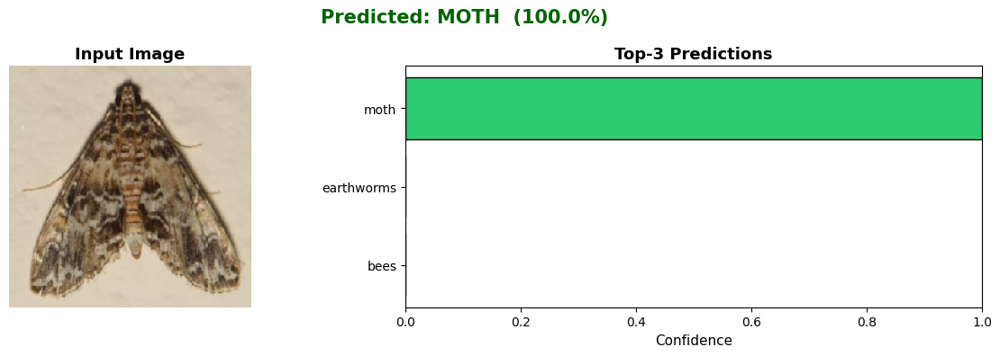

  Actual: moth            | Predicted: moth            | CORRECT



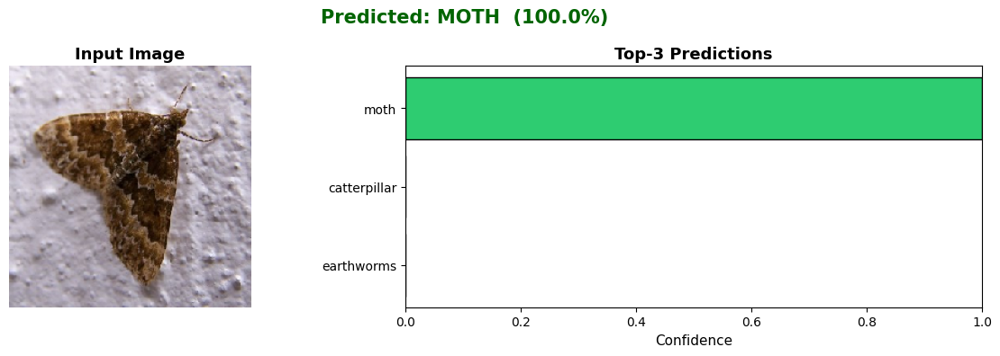

  Actual: moth            | Predicted: moth            | CORRECT



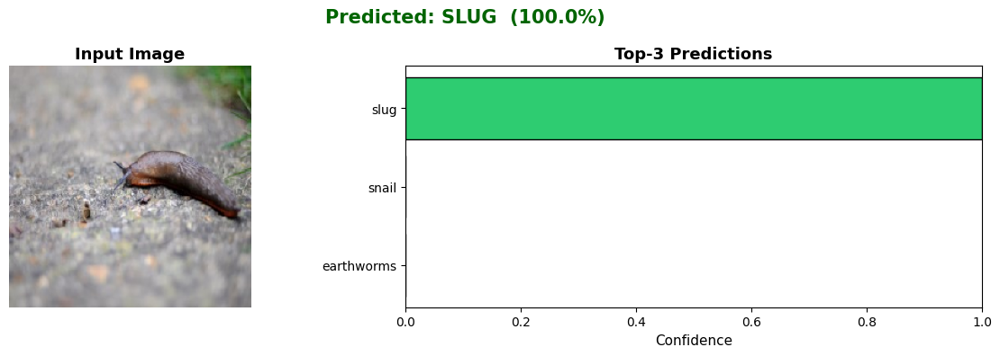

  Actual: slug            | Predicted: slug            | CORRECT



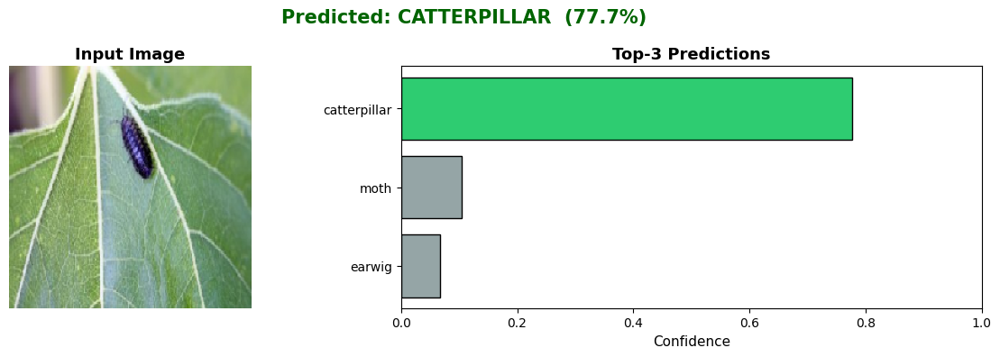

  Actual: earwig          | Predicted: catterpillar    | WRONG



In [26]:
# Demo: predict on a few random test images
print("Inference Demos on Random Test Images")
print("=" * 50)

demo_samples = test_df.sample(4, random_state=SEED)

for _, row in demo_samples.iterrows():
    result = predict_pest(row['image_path'])
    actual = row['label']
    match = "CORRECT" if result['predicted_class'] == actual else "WRONG"
    print(f"  Actual: {actual:<15s} | Predicted: {result['predicted_class']:<15s} | {match}")
    print()

---
## 9. Model Export

In [27]:
# Save the best model in both .keras and .h5 formats
import json as _json

SAVE_DIR = os.path.join(DATA_PATH, "saved_models")
os.makedirs(SAVE_DIR, exist_ok=True)

# Save model
model_path = os.path.join(SAVE_DIR, "best_pest_classifier.keras")
best_model.save(model_path)
print(f"Model saved to: {model_path}")

# Save class mapping
class_map_path = os.path.join(SAVE_DIR, "class_mapping.json")
with open(class_map_path, 'w') as f:
    _json.dump(class_indices, f, indent=2)
print(f"Class mapping saved to: {class_map_path}")

# Save metadata
metadata = {
    'model_name': best_name,
    'test_accuracy': float(best_acc),
    'image_size': list(IMAGE_SIZE),
    'num_classes': NUM_CLASSES,
    'preprocess_mode': best_preprocess,
    'class_names': class_names
}
meta_path = os.path.join(SAVE_DIR, "model_metadata.json")
with open(meta_path, 'w') as f:
    _json.dump(metadata, f, indent=2)
print(f"Metadata saved to: {meta_path}")

print(f"\n{'='*50}")
print("PIPELINE COMPLETE")
print(f"{'='*50}")

Model saved to: /content/dataset/saved_models/best_pest_classifier.keras
Class mapping saved to: /content/dataset/saved_models/class_mapping.json
Metadata saved to: /content/dataset/saved_models/model_metadata.json

PIPELINE COMPLETE


---
## How to Load & Use the Saved Model

```python
import tensorflow as tf
import json
import numpy as np

# Load model
model = tf.keras.models.load_model("saved_models/best_pest_classifier.keras")

# Load class names
with open("saved_models/model_metadata.json") as f:
    meta = json.load(f)

# Predict
img = tf.keras.preprocessing.image.load_img("path/to/image.jpg", target_size=(224, 224))
img_array = tf.keras.preprocessing.image.img_to_array(img)
img_array = np.expand_dims(img_array, axis=0)

# Apply preprocessing based on metadata
if meta['preprocess_mode'] == 'resnet':
    img_array = tf.keras.applications.resnet50.preprocess_input(img_array)
else:
    img_array = img_array / 255.0

preds = model.predict(img_array)
predicted_class = meta['class_names'][preds.argmax()]
confidence = preds.max()
print(f"Predicted: {predicted_class} ({confidence:.1%})")
```

In [28]:
import zipfile
import os

zip_file_path = '/content/agricultural-pests-image-dataset.zip'
extract_dir = '/content/dataset'

os.makedirs(extract_dir, exist_ok=True)

with zipfile.ZipFile(zip_file_path, 'r') as zip_ref:
   zip_ref.extractall(extract_dir)

print(f"'{zip_file_path}' unzipped to '{extract_dir}'")


'/content/agricultural-pests-image-dataset.zip' unzipped to '/content/dataset'
